In [1]:
!pip install deepchem rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 552.4/552.4 kB 6.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.5/29.5 MB 14.3 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [deepchem]


In [2]:
import sys
import deepchem as dc
import rdkit
!pip install tf_keras
import os
os.environ['TF_USE_LEGACY_KERAS'] = 'True'
import deepchem as dc
dc.__version__

/usr/local/lib/python3.13/dist-packages/deepchem/feat/smiles_tokenizer.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING W&B installed but not logged in.  Run `wandb login` or set the WANDB_API_KEY env variable.
Instructions for updating:
experimental_relax_shapes is deprecated, use reduce_retracing instead
wandb: WARNING W&B installed but not logged in.  Run `wandb login` or set the WANDB_API_KEY env variable.


'2.5.0'

In [3]:
tasks, datasets, transformers = (
    dc.molnet.load_bace_regression(
        featurizer="ECFP",
        splitter="scaffold",
        transformers=[]
    )
)

In [9]:
pip install torch_geometric

In [6]:
import sys
import deepchem as dc
import rdkit

In [21]:
import torch
from rdkit import Chem
from torch_geometric.utils import from_rdmol

def convert_to_graphs(dataset):
    graphs = []

    for smiles, label in zip(dataset.ids, dataset.y.ravel()):
        # Convert SMILES to RDKit molecule
        mol = Chem.MolFromSmiles(smiles)

        if mol is None:
            raise ValueError(f"Invalid SMILES: {smiles}")

        # Convert RDKit molecule to PyG graph
        data = from_rdmol(mol)

        # Attach the corresponding pIC50 label
        data.y = torch.tensor([float(label)], dtype=torch.float32)

        graphs.append(data)

    return graphs

In [12]:
train, valid, test = datasets

In [23]:
train_graphs = convert_to_graphs(train)
valid_graphs = convert_to_graphs(valid)
test_graphs = convert_to_graphs(test)

print("Train:", len(train_graphs))
print("Validation:", len(valid_graphs))
print("Test:", len(test_graphs))

Train: 1210
Validation: 151
Test: 152


In [46]:
from torch_geometric.loader import DataLoader

from torch_geometric.loader import DataLoader

train_loader = DataLoader(
    train_graphs,
    batch_size=32,
    shuffle=True,
    generator=torch.Generator().manual_seed(42)
)

valid_loader = DataLoader(
    valid_graphs,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_graphs,
    batch_size=32,
    shuffle=False
)



In [47]:
import torch
import torch.nn.functional as F

from torch_geometric.nn import GCNConv, global_mean_pool
from torch_geometric.utils.smiles import x_map

class MolecularGCN(torch.nn.Module):
    def __init__(self, hidden_channels=32):
        super().__init__()

        # One embedding layer for each categorical atom feature
        self.embeddings = torch.nn.ModuleList([
            torch.nn.Embedding(
                num_embeddings=len(categories),
                embedding_dim=hidden_channels
            )
            for categories in x_map.values()
        ])

        # Graph convolution layers
        self.conv1 = GCNConv(hidden_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, hidden_channels)

        # Predict one pIC50 per molecule
        self.output = torch.nn.Linear(hidden_channels, 1)

    def forward(self, x, edge_index, batch):

        # Convert categorical indices into embeddings
        x = sum(
            embedding(x[:, i].long())
            for i, embedding in enumerate(self.embeddings)
        )

        # Graph convolutions
        x = self.conv1(x, edge_index)
        x = F.relu(x)

        x = self.conv2(x, edge_index)
        x = F.relu(x)

        # Pool atoms into one molecular representation
        x = global_mean_pool(x, batch)

        # Regression output
        return self.output(x).view(-1)

In [48]:
import random
import numpy as np
import torch

seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Fresh model
model = MolecularGCN(hidden_channels=32).to(device)

# Fresh optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

loss_fn = torch.nn.MSELoss()

In [49]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = MolecularGCN(hidden_channels=32).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

loss_fn = torch.nn.MSELoss()

def train():
    model.train()
    total_loss = 0
    total_molecules = 0

    for batch in train_loader:
        batch = batch.to(device)

        # Reset gradients
        optimizer.zero_grad()

        # Predict pIC50 for each molecule
        predictions = model(
            batch.x,
            batch.edge_index,
            batch.batch
        )

        # Calculate error
        loss = loss_fn(predictions, batch.y.view(-1))

        # Backpropagation
        loss.backward()

        # Update model parameters
        optimizer.step()

        # Accumulate loss across all molecules
        total_loss += loss.item() * batch.num_graphs
        total_molecules += batch.num_graphs

    return total_loss / total_molecules

In [50]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

@torch.no_grad()
def evaluate(loader):
    model.eval()

    all_predictions = []
    all_targets = []

    for batch in loader:
        batch = batch.to(device)

        predictions = model(
            batch.x,
            batch.edge_index,
            batch.batch
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_targets.extend(
            batch.y.view(-1).cpu().numpy()
        )

    actual = np.array(all_targets)
    predicted = np.array(all_predictions)

    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }

In [52]:
import copy

best_mae = float("inf")
best_state = None
best_epoch = None

train_history = []
valid_history = []

for epoch in range(1, 201):
    train_loss = train()
    metrics = evaluate(valid_loader)

    train_history.append(train_loss)
    valid_history.append(metrics["MAE"])

    if metrics["MAE"] < best_mae:
        best_mae = metrics["MAE"]
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())

    if epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"Train MSE: {train_loss:.4f} | "
            f"Valid MAE: {metrics['MAE']:.4f}"
        )

# Restore best model parameters
model.load_state_dict(best_state)

print(f"Best epoch: {best_epoch}")
print(f"Best validation MAE: {best_mae:.4f}")

Epoch 010 | Train MSE: 0.8998 | Valid MAE: 0.7440
Epoch 020 | Train MSE: 0.8838 | Valid MAE: 0.6755
Epoch 030 | Train MSE: 0.8735 | Valid MAE: 0.7294
Epoch 040 | Train MSE: 0.8717 | Valid MAE: 0.6051
Epoch 050 | Train MSE: 0.8640 | Valid MAE: 0.9178
Epoch 060 | Train MSE: 0.8234 | Valid MAE: 0.6081
Epoch 070 | Train MSE: 0.8271 | Valid MAE: 0.7675
Epoch 080 | Train MSE: 0.8626 | Valid MAE: 0.6709
Epoch 090 | Train MSE: 0.8283 | Valid MAE: 0.6515
Epoch 100 | Train MSE: 0.7802 | Valid MAE: 0.7897
Epoch 110 | Train MSE: 0.7978 | Valid MAE: 0.6675
Epoch 120 | Train MSE: 0.7749 | Valid MAE: 0.6183
Epoch 130 | Train MSE: 0.7512 | Valid MAE: 0.6540
Epoch 140 | Train MSE: 0.7523 | Valid MAE: 0.6585
Epoch 150 | Train MSE: 0.7626 | Valid MAE: 0.6624
Epoch 160 | Train MSE: 0.7383 | Valid MAE: 0.7524
Epoch 170 | Train MSE: 0.7687 | Valid MAE: 0.8708
Epoch 180 | Train MSE: 0.7101 | Valid MAE: 0.7035
Epoch 190 | Train MSE: 0.6917 | Valid MAE: 0.6849
Epoch 200 | Train MSE: 0.6904 | Valid MAE: 0.6121


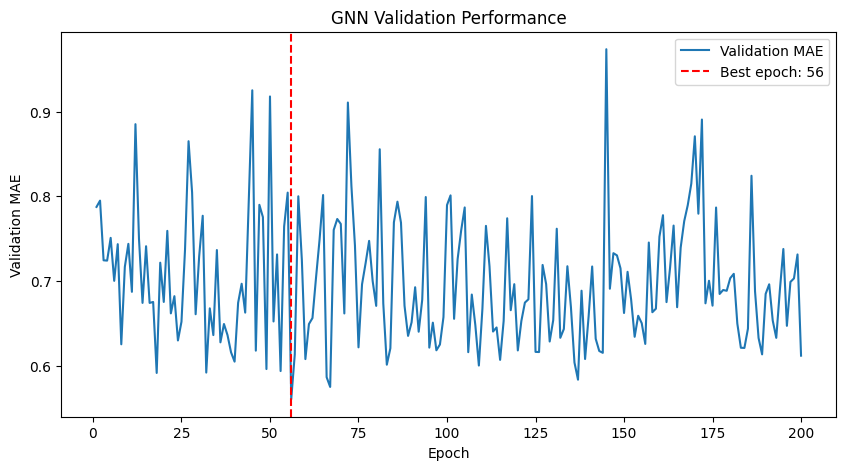

In [53]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 201),
    valid_history,
    label="Validation MAE"
)

plt.axvline(
    best_epoch,
    color="red",
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Validation MAE")
plt.title("GNN Validation Performance")
plt.legend()
plt.show()

GNN validation results:
MAE:  0.5608
RMSE: 0.7273
R²:   -1.1441


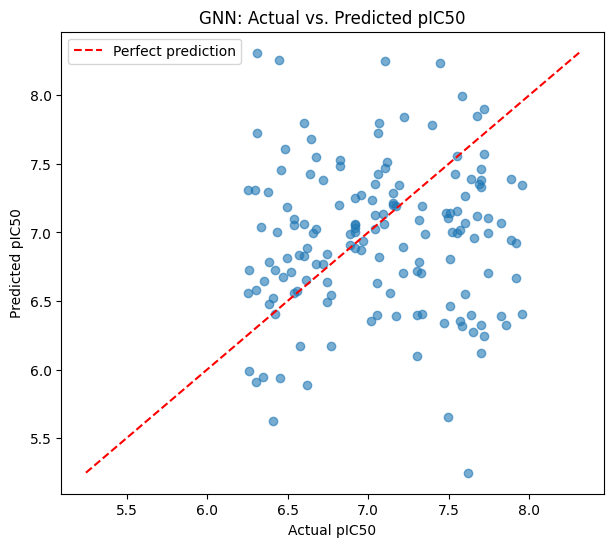

In [54]:
gnn_metrics = evaluate(valid_loader)


print("GNN validation results:")
print(f"MAE:  {gnn_metrics['MAE']:.4f}")
print(f"RMSE: {gnn_metrics['RMSE']:.4f}")
print(f"R²:   {gnn_metrics['R2']:.4f}")


model.eval()

gnn_predictions = []
gnn_actual = []

with torch.no_grad():
    for batch in valid_loader:
        batch = batch.to(device)

        preds = model(
            batch.x,
            batch.edge_index,
            batch.batch
        )

        gnn_predictions.extend(preds.cpu().numpy())
        gnn_actual.extend(batch.y.view(-1).cpu().numpy())

gnn_predictions = np.array(gnn_predictions)
gnn_actual = np.array(gnn_actual)

plt.figure(figsize=(7, 6))

plt.scatter(
    gnn_actual,
    gnn_predictions,
    alpha=0.6
)

limits = [
    min(gnn_actual.min(), gnn_predictions.min()),
    max(gnn_actual.max(), gnn_predictions.max())
]

plt.plot(limits, limits, "r--", label="Perfect prediction")
plt.xlabel("Actual pIC50")
plt.ylabel("Predicted pIC50")
plt.title("GNN: Actual vs. Predicted pIC50")
plt.legend()
plt.show()

In [56]:
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    r2_score
)

actual = valid.y.ravel()

# GNN predictions must be in the same order as valid.y
print("GNN MAE:", mean_absolute_error(actual, gnn_predictions))
print("GNN R²:", r2_score(actual, gnn_predictions))

# Constant baseline using training-set mean
train_ds, valid_ds, test_ds = datasets

dummy_predictions = np.full(
    len(actual),
    train_ds.y.mean()
)

print("Dummy MAE:", mean_absolute_error(actual, dummy_predictions))
print("Dummy R²:", r2_score(actual, dummy_predictions))

print("Dummy MAE:", mean_absolute_error(actual, dummy_predictions))
print("Dummy R²:", r2_score(actual, dummy_predictions))

GNN MAE: 0.5607776215655801
GNN R²: -1.1441384162350587
Dummy MAE: 0.670179356399759
Dummy R²: -1.7070079140248917
Dummy MAE: 0.670179356399759
Dummy R²: -1.7070079140248917


In [42]:
import numpy as np

best_epoch_from_history = np.argmin(valid_history) + 1
best_mae_from_history = np.min(valid_history)

print("History length:", len(valid_history))
print("Best epoch from history:", best_epoch_from_history)
print("Best MAE from history:", best_mae_from_history)

print("Stored best epoch:", best_epoch)
print("Stored best MAE:", best_mae)

History length: 200
Best epoch from history: 155
Best MAE from history: 0.5697919726371765
Stored best epoch: 155
Stored best MAE: 0.5697919726371765


In [57]:
import numpy as np
from sklearn.metrics import mean_absolute_error, r2_score

actual = valid_ds.y.ravel()

median_predictions = np.full(
    len(actual),
    np.median(train_ds.y)
)

print("Training median:", np.median(train_ds.y))
print("Median MAE:", mean_absolute_error(actual, median_predictions))
print("Median R²:", r2_score(actual, median_predictions))

Training median: 6.5850267
Median MAE: 0.5632744622516557
Median R²: -0.9526499378674598


In [60]:
from pathlib import Path

save_dir = Path("/content/ActiveScreen/results")
save_dir.mkdir(parents=True, exist_ok=True)

print("Saving to:", save_dir)

Saving to: /content/ActiveScreen/results


In [62]:
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "hidden_channels": 32,
        "best_epoch": best_epoch,
        "best_validation_mae": best_mae
    },
    save_dir / "gnn_checkpoint.pt"
)

In [63]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/ActiveScreen_results",
    "zip",
    "/content/ActiveScreen/results"
)

files.download("/content/ActiveScreen_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>